In [1]:
import h2o
import numpy as np
import pandas as pd
import psycopg2
from h2o.estimators import H2OExtendedIsolationForestEstimator, H2ORandomForestEstimator
import warnings
import json
from sklearn.metrics import mean_squared_error
h2o.init(nthreads=-1,enable_assertions=False)
warnings.filterwarnings('ignore')

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
; Java HotSpot(TM) 64-Bit Server VM (build 25.391-b13, mixed mode)
  Starting server from C:\T0001\dse\Python\Lib\site-packages\h2o\backend\bin\h2o.jar
  Ice root: C:\Users\DAN~1.LAR\AppData\Local\Temp\3\tmp2dnq3mzj
  JVM stdout: C:\Users\DAN~1.LAR\AppData\Local\Temp\3\tmp2dnq3mzj\h2o_dan_larson_started_from_python.out
  JVM stderr: C:\Users\DAN~1.LAR\AppData\Local\Temp\3\tmp2dnq3mzj\h2o_dan_larson_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,03 secs
H2O_cluster_timezone:,America/New_York
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.44.0.2
H2O_cluster_version_age:,2 months and 22 days
H2O_cluster_name:,H2O_from_python_dan_larson_zdqn84
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.477 Gb
H2O_cluster_total_cores:,4
H2O_cluster_allowed_cores:,4
H2O_cluster_status:,"locked, healthy"


In [2]:

dat = h2o.import_file(f"C:/MLAR_DATA/T0001/MLAR_RAW_SERES.parquet")

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


In [68]:
dat = dat.fillna(method='forward',axis=0,maxlen=1)


In [50]:
unsupervisedFeatures  = list(dat.columns) #'T_AUDITSCANNED','T_AUDITSCAN_SEVERITY'


In [4]:
dat.insert_missing_values()

Insert Missing Values progress: |

████████████████████████████████████████████████| (done) 100%


audit_table_name,audit_action,audit_timestamp,audit_type,audit_counter,trans_order,table_name,table_key,reason,record_signed,user_name,user_role,parent_table,parent_key,batch_name,col_num,document_number,experiment_number,row_num,workbook_number,worksheet,formulation,investigation,order_num,project_name,name,report_number,sample_number,location_number,t_mlar,t_mlar_severity,SAMPLE_NUMBER_norm,TEST_NUMBER_norm,RESULT_NUMBER_norm,ORDER_NUMBER_norm,ANALYSIS_norm,NAME_norm,REPORTED_NAME_norm,REPLICATE_COUNT_norm,RESULT_TYPE_norm,STATUS_norm,OLD_STATUS_norm,MODIFIED_RESULT_norm,ALLOW_OUT_norm,UNITS_norm,ROUND_norm,PLACES_norm,IN_SPEC_norm,PRIMARY_IN_SPEC_norm,USES_INSTRUMENT_norm,USES_CODES_norm,IN_CAL_norm,AUTO_CALC_norm,ALLOW_CANCEL_norm,LINK_SIZE_norm,REPORTABLE_norm,OPTIONAL_norm,CODE_ENTERED_norm,CHANGED_ON_norm,STD_REAG_SAMPLE_norm,HAS_ATTRIBUTES_norm,FACTOR_VALUE_norm,IN_CONTROL_norm,DISPLAYED_norm,SPEC_OVERRIDE_norm,T_PH_AQL_REPS_norm,SAP_CONFIRMATION_NO_norm,SAP_REPLICATES_norm,SAPPED_norm,SAP_OPTIONAL_norm,T_SUPPLIED_RSLT_USED_norm,PLACES_2_norm,REPORTED_RESULT_norm,REPORTED_RSLT_REV_norm,REPORTED_RSLT_OOS_norm,FROM_INSTRUMENT_norm,TEXT_ID_norm,RE_SAMPLE_norm,ALIQUOT_norm,ORIGINAL_SAMPLE_norm,PARENT_SAMPLE_norm,PARENT_ALIQUOT_norm,SAMPLE_VOLUME_norm,SAMPLE_UNITS_norm,LOGIN_DATE_norm,LOGIN_BY_norm,STARTED_norm,PREP_norm,PRODUCT_norm,PRODUCT_VERSION_norm,PRODUCT_GRADE_norm,SAMPLING_POINT_norm,PRIORITY_norm,TEMPLATE_norm,STANDARD_norm,LOT_norm,PARTIAL_SPEC_norm,SPEC_TYPE_norm,STAGE_norm,RELEASED_norm,INVESTIGATED_norm,APPROVED_norm,READY_FOR_APPROVAL_norm,APPROVAL_ID_norm,MODIFIED_RESULTS_norm,REPORT_NUMBER_norm,COMPOSITE_norm,PARENT_COMPOSITE_norm,PEOPLE_norm,TEST_LOCATION_norm,CHK_ALIQUOT_STATUS_norm,CHK_ALIQUOT_SPECS_norm,SAMPLE_EVENT_norm,HAS_FLAGS_norm,SAMPLED_norm,NUM_CONTAINERS_norm,REQD_VOLUME_norm,COLLECTION_OFFSET_norm,SIGNED_norm,ALLOW_CHLD_ALQTS_norm,IS_TIME_ZERO_norm,STORAGE_LOC_NO_norm,GROUP_NAME_norm,FACILITY_norm,ON_WORKBOOK_norm,T_PH_RELATED_LOT_norm,T_PH_MV_PROT_VERSION_norm,T_PH_MV_REPLICATE_norm,INSPECT_PNT_NUM_norm,IS_INSPECT_PNT_norm,SCHEDULE_NUMBER_norm,T_ACTION_NUMBER_norm,T_EM_PLAN_norm,T_ORIGINAL_SAMPLE_norm,T_VALIDATION_norm,T_USE_SUPPLIED_RSLT_norm,T_PH_ACTION_DONE_norm,T_PH_ACTION_REQD_norm,T_PH_CYCLING_DONE_norm,T_PH_CYCLING_REQD_norm,T_PH_RETURN_REQD_norm,T_PH_RETURNED_norm,SPEC_LIST_VERSION_norm,NEEDS_AUDIT_REVIEW_norm,AUDIT_REVIEWED_norm,TRACK_CHANGES_norm,T_ACTUAL_QUANTITY_norm,T_CONTAINER_VOLUME_norm,T_NUM_TEST_ALIQUOTS_norm,T_REQUIRES_SAMPLING_norm,T_REQUIRES_SLM_norm,T_SAMPLE_PLAN_ENTRY_norm,VERSION_norm,ANALYSIS_COUNT_norm,BATCH_PARENT_TEST_norm,BATCH_SIBLING_TEST_norm,PARENT_TEST_norm,ORIGINAL_TEST_norm,REPLICATE_TEST_norm,TEST_PRIORITY_norm,RESOLVE_REQD_norm,RE_TESTED_norm,ALIQUOTED_TO_norm,ON_WORKSHEET_norm,DISPLAY_RESULTS_norm,SPLIT_REPLICATES_norm,CROSS_SAMPLE_norm,DOUBLE_ENTRY_norm,CHILD_OUT_SPEC_norm,CHARGE_ENTRY_norm,BATCH_ORIGINAL_TEST_norm,TEST_SEQUENCE_NO_norm,AQL_PLAN_VERSION_norm,AQL_CRITICAL_norm,AQL_MAJOR_norm,AQL_MINOR_norm,AQL_norm,AQL_UPPER_norm,AQL_LOWER_norm,AQL_SAMPLE_SIZE_norm,AQL_SAMPLE_SIZE2_norm,SAP_LONG_TERM_norm,T_NUM_STAGES_norm,T_AUTO_ADD_STAGE_norm,METHOD_VERSION_norm,T_TESTING_INTERVAL_norm,LIST_KEY_norm,SAMPLED_DATE_norm,LOCATION_norm,SAMPLED_BY_norm,T_ACTUAL_UNITS_norm,T_RECEIPT_DUE_DATE_norm,DATE_RECEIVED_norm,RECD_DATE_norm,RECEIVED_BY_norm,DUE_DATE_norm,ENTRY_norm,FORMATTED_ENTRY_norm,NUMERIC_ENTRY_norm,ENTERED_ON_norm,ENTERED_BY_norm,ENTRY_TYPE_norm,ENTRY_QUALIFIER_norm,DATE_STARTED_norm,DATE_COMPLETED_norm,DESCRIPTION_norm,T_COLLECT_SCHEME_norm,AVAILABLE_DATE_norm,REQUIRED_DATE_norm,TARGET_DATE_norm,COMPOSITE_TEMPLATE_norm,PLANT_norm,PROCESS_UNIT_norm,T_SAMPLE_TYPE_norm,T_SUITE_norm,T_EM_SAMPLE_TYPE_norm,T_NEXT_STAGE_ANALYSIS_norm,PHASE_norm,BATCH_norm,T_INCUB1_BATCH_norm,T_INCUB1_END_norm,T_INCUB1_START_norm,DATE_REVIEWED_norm,REVIEWER_norm,T_PERSONNEL_norm,T_PERSONNEL_SET_norm,ASSIGNED_OPERATOR_norm,DATE_ENTRY_norm,TEST_COMMENT_norm,METHOD_norm,AUD

In [6]:
from h2o.estimators import H2OIsolationForestEstimator



In [37]:
dat

AttributeError: 'H2OFrame' object has no attribute 'dtypes'

In [51]:
dat['FORMATTED_ENTRY_norm'].describe()

Rows:523460
Cols:1

,FORMATTED_ENTRY_norm
type,real
mins,-999.0
mean,12994234356.976059
maxs,2490368000000005.0
sigma,4994936805662.09
zeros,9532
missing,71535
0,-999.0
1,-999.0
2,-999.0


None


In [7]:
isolation_model = H2OIsolationForestEstimator(model_id = f"seres_model1.hex", seed = 1234,
                                              ignore_const_cols=True ,
                                              missing_value_handling="PlugValues",
                      ntrees = 100,
                      sample_size = 256)
isolation_model.train(training_frame = dat, x = unsupervisedFeatures)

TypeError: H2OIsolationForestEstimator.__init__() got an unexpected keyword argument 'missing_value_handling'

In [7]:
h2o.save_model(isolation_model,"C:/Users/dan.larson/Documents/MLAR/models/Expirement_0")

'C:\\Users\\dan.larson\\Documents\\MLAR\\models\\Expirement_0\\seres_model1.hex'

In [8]:
predictions = isolation_model.predict(dat)
predictions.head()

isolationforest prediction progress: |███████████████████████████████████████████| (done) 100%


predict,mean_length
0.596899,4.12
0.627907,4.04
0.751938,3.72
0.666667,3.94
0.651163,3.98
0.674419,3.92
0.852713,3.46
0.852713,3.46
0.705426,3.84
0.643411,4


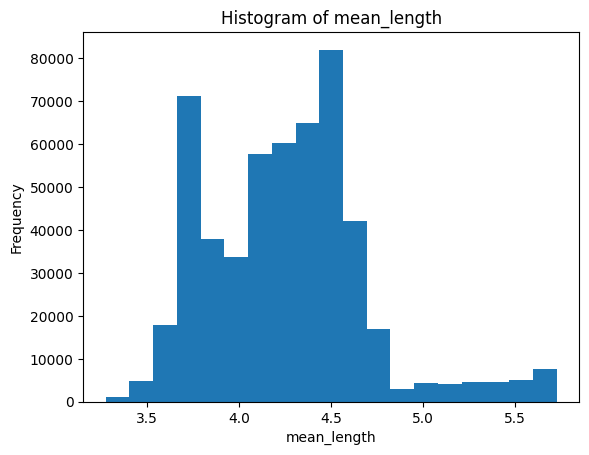

breaks,counts,mids_true,mids,widths
3.209,nan,nan,nan,nan
3.338,1157,1.54,3.2735,0.129
3.467,4731,1.61,3.4025,0.129
3.596,17828,1.67,3.5315,0.129
3.725,71259,1.74,3.6605,0.129
3.854,37951,1.8,3.7895,0.129
3.983,33613,1.87,3.9185,0.129
4.112,57727,1.93,4.0475,0.129
4.241,60325,2,4.1765,0.129
4.37,64867,2.06,4.3055,0.129


In [10]:
predictions['mean_length'].hist()

## Understanding the base model


In [ ]:
global_surrogate_data = dat[:, :]
global_surrogate_data["anomaly"] = (predictions["mean_length"] < 5.8).ifelse("Yes", "No")
global_surrogate_data["anomaly"].table()

anomaly,Count
No,496094
Yes,27366


In [ ]:
from h2o.estimators import H2ORandomForestEstimator

global_surrogate_dt = H2ORandomForestEstimator(model_id = "global_surrogate_decision_tree.hex", 
                                               ntrees = 1, max_depth = 3,
                                               sample_rate = 1, mtries = -1,
                                               categorical_encoding= 'one_hot_explicit')
global_surrogate_dt.train(training_frame = global_surrogate_data, x = fieldDictUnsupervised, y = "anomaly")

drf Model Build progress: |██████████████████████████████████████████████████████| (done) 100%


Model Details
=============
H2ORandomForestEstimator : Distributed Random Forest
Model Key: global_surrogate_decision_tree.hex


Model Summary: 
    number_of_trees    number_of_internal_trees    model_size_in_bytes    min_depth    max_depth    mean_depth    min_leaves    max_leaves    mean_leaves
--  -----------------  --------------------------  ---------------------  -----------  -----------  ------------  ------------  ------------  -------------
    1                  1                           146                    3            3            3             7             7             7

ModelMetricsBinomial: drf
** Reported on train data. **

MSE: NaN
RMSE: NaN
LogLoss: NaN
Mean Per-Class Error: NaN
AUC: NaN
AUCPR: NaN
Gini: NaN

Scoring History: 
    timestamp            duration    number_of_trees    training_rmse    training_logloss    training_auc    training_pr_auc    training_lift    training_classification_error
--  -------------------  ----------  -----------------  ---------------  ------------------  --------------  -----------------  ---------------  -------------------------------
    2024-01-29 16:17:36  1.088 sec   0                  nan              nan                 nan             nan                nan              nan

Variable Importances: 
variable                     relative_importance    scaled_importance    percentage
---------------------------  ---------------------  -------------------  -------------------
audit_type.ReactivateSample  359.16943359375        1.0                  0.3827919649299977
volacity                     190.562744140625       0.5305650378817232   0.20309603337390345
audit_type.ModifySample      190.1365509033203      0.5293784301210339   0.20264180945758803
user_role._SUPERVISOR        143.5072021484375      0.39955293721000734  0.1529456539281707
distinct_users               36.90065002441406      0.10273883736485136  0.03932760142951492
seconds_to_process           18.012271881103516     0.05014979059013376  0.01919693688082521
audit_timestamp              0.0                    0.0                  0.0
audit_counter                0.0                    0.0                  0.0
trans_order                  0.0                    0.0                  0.0
audit_count                  0.0                    0.0                  0.0
---                          ---                    ---                  ---
OLD_STATUS_norm.C            0.0                    0.0                  0.0
OLD_STATUS_norm.E            0.0                    0.0                  0.0
OLD_STATUS_norm.I            0.0                    0.0                  0.0
OLD_STATUS_norm.M            0.0                    0.0                  0.0
OLD_STATUS_norm.N            0.0                    0.0                  0.0
OLD_STATUS_norm.P            0.0                    0.0                  0.0
OLD_STATUS_norm.R            0.0                    0.0                  0.0
OLD_STATUS_norm.U            0.0                    0.0                  0.0
OLD_STATUS_norm.X            0.0                    0.0                  0.0
OLD_STATUS_norm.missing(NA)  0.0                    0.0                  0.0
[71 rows x 4 columns]


[tips]
Use `model.explain()` to inspect the model.
--
Use `h2o.display.toggle_user_tips()` to switch on/off this section.

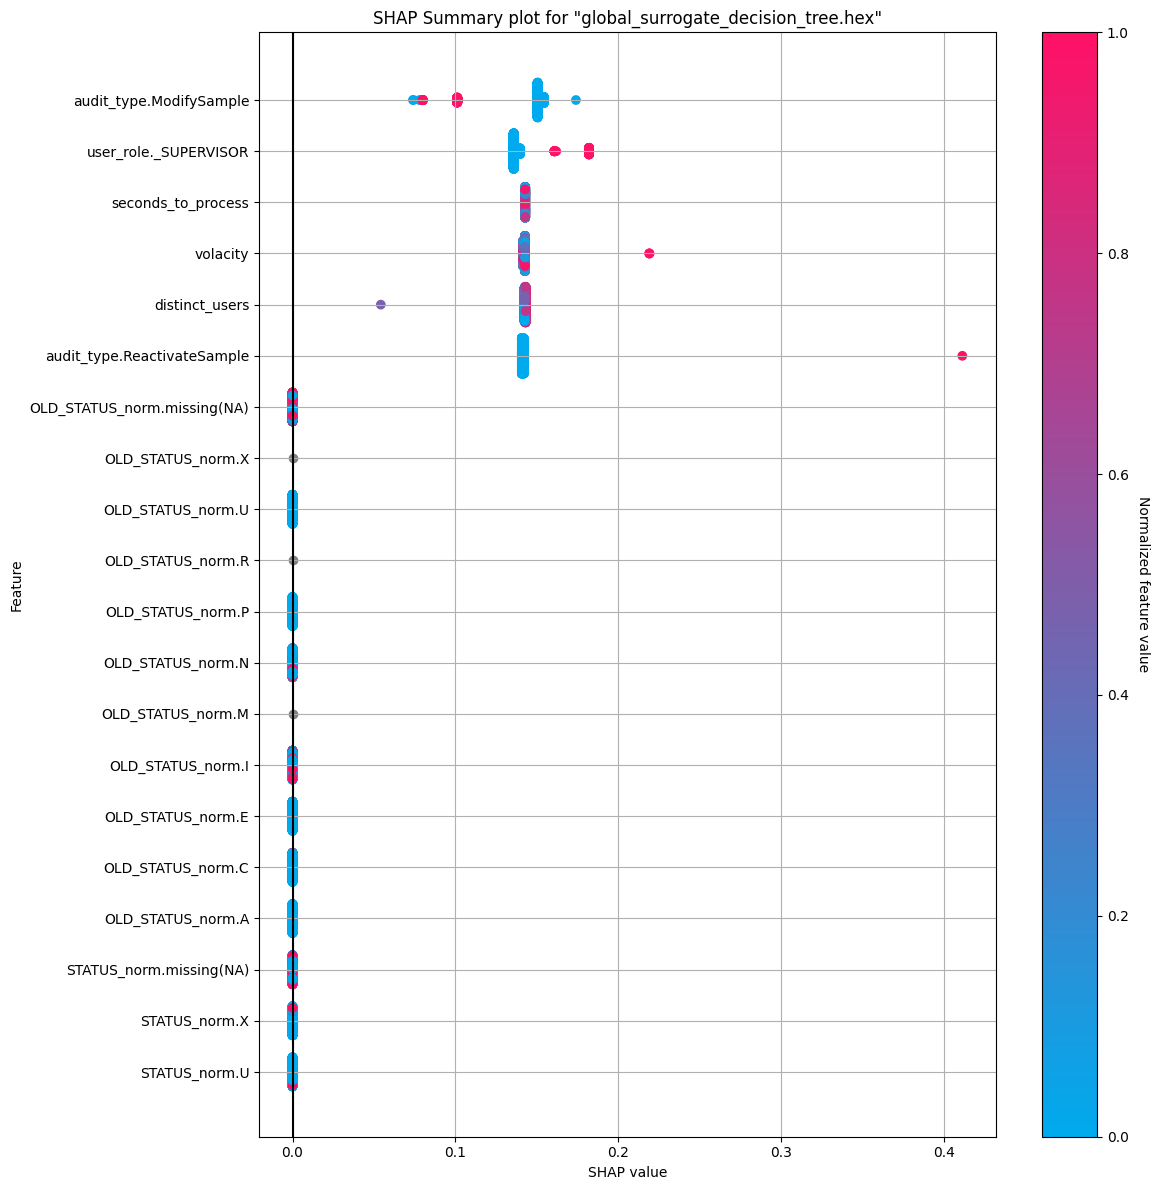

In [ ]:
global_surrogate_dt.shap_summary_plot(dat)

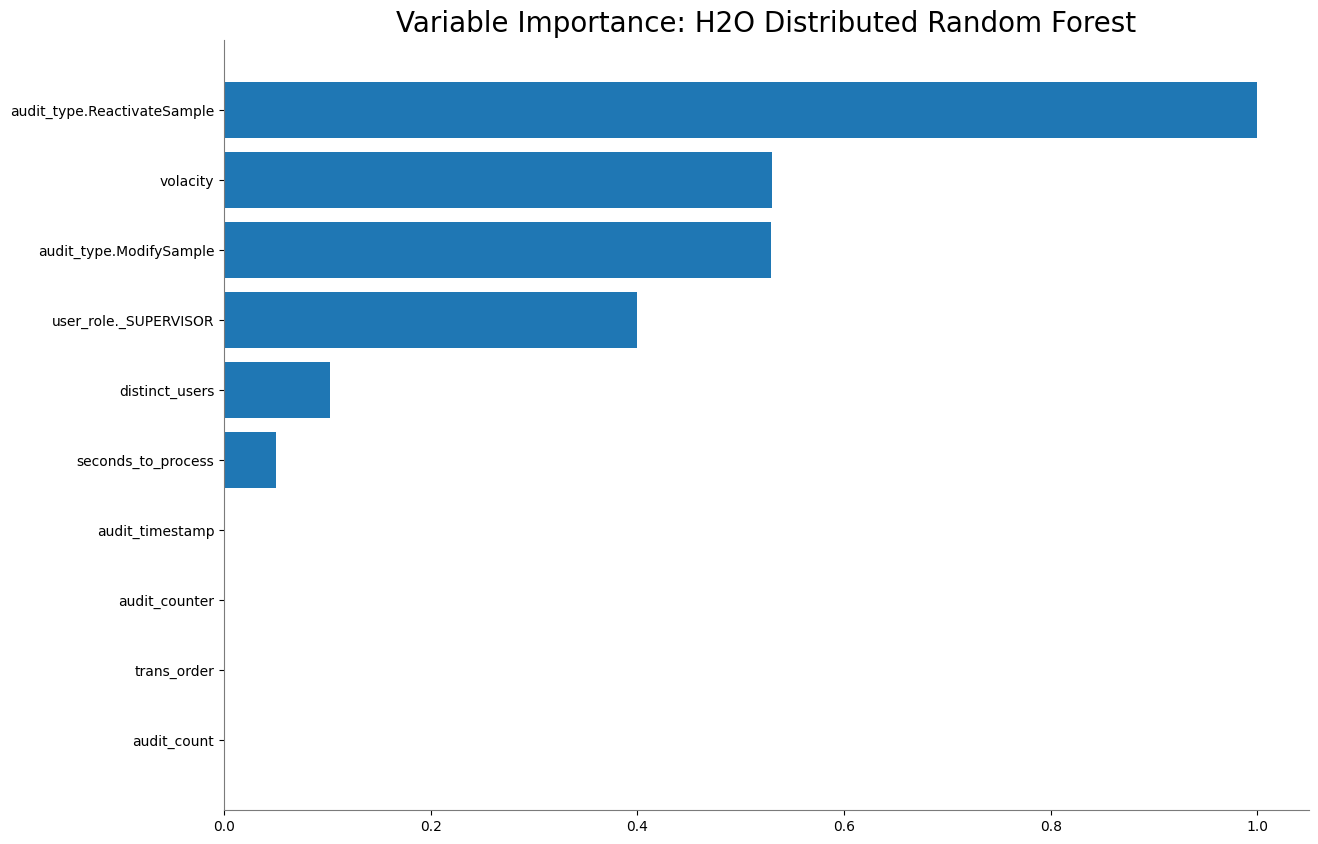

<Figure size 640x480 with 0 Axes>

In [ ]:
global_surrogate_dt.varimp_plot()

In [48]:
saas_customers = ['jaguar','locusbio','seres','tenaya']

df = pd.DataFrame()

for saas in ['jaguar','locusbio','seres','tenaya']: 
    for saas_2 in ['jaguar','locusbio','seres','tenaya']: 
        if saas_2 == saas:
            print('same')
        else:
            dat = h2o.import_file(f"C:/MLAR_DATA/for_model/T0001/{saas_2}_model_ready.parquet")
            saas_2_model = h2o.load_model(f'C:\\Users\\dan.larson\\Documents\\MLAR\\models\\{saas_2}_model1.hex')
            predictions = saas_2_model.predict(dat)
            saas_model = h2o.load_model(f'C:\\Users\\dan.larson\\Documents\\MLAR\\models\\{saas}_model1.hex')
            other = saas_model.predict(dat)
            test = predictions.cbind(other)
            test = test.as_data_frame()
            ml_main = test['mean_length'].quantile(0.10)
            ml_other = test['mean_length0'].quantile(0.10)
            test['anomaly_1'] = np.where(test["mean_length"] < ml_main, "Yes", "No")
            test['anomaly_2'] = np.where(test["mean_length0"] < ml_other, "Yes", "No")

            ct = pd.crosstab(test['anomaly_1'], test['anomaly_2'])
            print(ct)
            new_rows_df = pd.DataFrame(ct)
            new_rows_df['model_trained'] = saas
            new_rows_df['data_tested'] = saas_2
            df = pd.concat([df, new_rows_df], ignore_index=True)


same
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
isolationforest prediction progress: |███████████████████████████████████████████| (done) 100%
isolationforest prediction progress: |███████████████████████████████████████████| (done) 100%
anomaly_2      No    Yes
anomaly_1               
No         554695  40720
Yes         41701  20306
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
isolationforest prediction progress: |███████████████████████████████████████████| (done) 100%
isolationforest prediction progress: |███████████████████████████████████████████| (done) 100%
anomaly_2      No    Yes
anomaly_1               
No         438873  32704
Yes         35967  15916
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
isolationforest prediction progress: |███████████████████████████████████████████| (done) 100%
isolationforest prediction progress

In [49]:
df

anomaly_2,No,Yes,model_trained,data_tested
0,554695,40720,jaguar,locusbio
1,41701,20306,jaguar,locusbio
2,438873,32704,jaguar,seres
3,35967,15916,jaguar,seres
4,248882,17867,jaguar,tenaya
5,19932,8795,jaguar,tenaya
6,496736,19031,locusbio,jaguar
7,17982,37558,locusbio,jaguar
8,427180,44397,locusbio,seres
9,45484,6399,locusbio,seres


In [10]:
ml_main = test['mean_length'].quantile(0.05)
ml_other = test['mean_length0'].quantile(0.05)

In [11]:
test['anomaly_1'] = np.where(test["mean_length"]  < ml_main,"Yes", "No")
test['anomaly_2'] = np.where(test["mean_length0"] < ml_other,"Yes", "No")
            
pd.crosstab(test['anomaly_1'], test['anomaly_2'])

anomaly_2,No,Yes
anomaly_1,,
No,543406,0
Yes,0,27901


<Axes: >

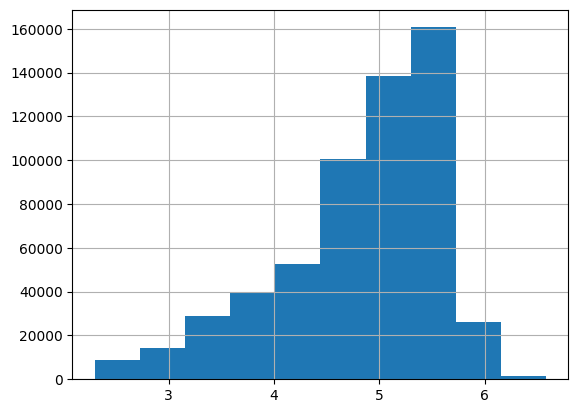

In [13]:
test['mean_length'].hist()

In [44]:
dat = h2o.import_file(f"C:/MLAR_DATA/for_model/T0001/seres_model_ready.parquet")
saas_2_model = h2o.load_model(f'C:\\Users\\dan.larson\\Documents\\MLAR\\models\\seres_model1.hex')
predictions = saas_2_model.predict(dat)
saas_model = h2o.load_model(f'C:\\Users\\dan.larson\\Documents\\MLAR\\models\\jaguar_model1.hex')
other = saas_model.predict(dat)
test = predictions.cbind(other)
test = test.as_data_frame()
ml_main = test['mean_length'].quantile(0.10)
ml_other = test['mean_length0'].quantile(0.10)
test['anomaly_1'] = np.where(test["mean_length"] < ml_main, "Yes", "No")
test['anomaly_2'] = np.where(test["mean_length0"] < ml_other, "Yes", "No")

ct = pd.crosstab(test['anomaly_1'], test['anomaly_2'])
print(ct)
new_rows_df = pd.DataFrame(ct)
new_rows_df['model_trained'] = saas
new_rows_df['data_tested'] = saas_2
df = pd.concat([df, new_rows_df], ignore_index=True)

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
isolationforest prediction progress: |███████████████████████████████████████████| (done) 100%
isolationforest prediction progress: |███████████████████████████████████████████| (done) 100%
anomaly_2      No    Yes
anomaly_1               
No         438873  32704
Yes         35967  15916


In [61]:
test


,predict,mean_length,predict0,mean_length0,anomaly_1,anomaly_2
0,0.075862,6.18,0.322751,5.36,No,No
1,0.075862,6.18,0.328042,5.34,No,No
2,0.137931,6.00,0.365079,5.20,No,No
3,0.096552,6.12,0.370370,5.18,No,No
4,0.124138,6.04,0.322751,5.36,No,No
...,...,...,...,...,...,...
523455,0.144828,5.98,0.275132,5.54,No,No
523456,0.144828,5.98,0.275132,5.54,No,No
523457,0.117241,6.06,0.216931,5.76,No,No
523458,0.131034,6.02,0.222222,5.74,No,No


In [62]:
test2 = test.as_data_frame()

AttributeError: 'DataFrame' object has no attribute 'as_data_frame'

In [40]:
ml_main = test2['mean_length'].quantile(0.10)
test2['anomaly'] = np.where(test2["mean_length"] < ml_main, "Yes", "No")

In [60]:
test2

,predict,mean_length,predict0,mean_length0,anomaly
0,0.075862,6.18,0.075862,6.18,No
1,0.075862,6.18,0.075862,6.18,No
2,0.137931,6.00,0.137931,6.00,No
3,0.096552,6.12,0.096552,6.12,No
4,0.124138,6.04,0.124138,6.04,No
...,...,...,...,...,...
523455,0.144828,5.98,0.144828,5.98,No
523456,0.144828,5.98,0.144828,5.98,No
523457,0.117241,6.06,0.117241,6.06,No
523458,0.131034,6.02,0.131034,6.02,No


In [66]:
test

,predict,mean_length,predict0,mean_length0,anomaly_1,anomaly_2
0,0.075862,6.18,0.322751,5.36,No,No
1,0.075862,6.18,0.328042,5.34,No,No
2,0.137931,6.00,0.365079,5.20,No,No
3,0.096552,6.12,0.370370,5.18,No,No
4,0.124138,6.04,0.322751,5.36,No,No
...,...,...,...,...,...,...
523455,0.144828,5.98,0.275132,5.54,No,No
523456,0.144828,5.98,0.275132,5.54,No,No
523457,0.117241,6.06,0.216931,5.76,No,No
523458,0.131034,6.02,0.222222,5.74,No,No


In [67]:
mse = mean_squared_error(test['mean_length'], test['mean_length0'])

# Calculate RMSE
rmse = np.sqrt(mse)

In [68]:
rmse

1.054847776063063

In [54]:
!python -m pip install -U scikit-learn

  Using cached scikit_learn-1.4.0-1-cp312-cp312-win_amd64.whl.metadata (11 kB)
  Using cached joblib-1.3.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached threadpoolctl-3.2.0-py3-none-any.whl.metadata (10.0 kB)
Using cached scikit_learn-1.4.0-1-cp312-cp312-win_amd64.whl (10.6 MB)
Using cached joblib-1.3.2-py3-none-any.whl (302 kB)
Using cached threadpoolctl-3.2.0-py3-none-any.whl (15 kB)
